<a href="https://colab.research.google.com/github/erre-x-erre/Metodos_Numericos_I/blob/main/M%C3%A9todo%20de%20Diferencias%20Divididas%20de%20Newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#***<font color="green">"MÉTODO DE DIFERENCIAS DIVIDIDAS DE NEWTON".</font>***

Este método nos da el polinomio de Lagrange que pasa por {$x_0,x_1,\dots,x_n$}, $P_n(x)$, de manera sencilla escribiendolo así:

\begin{aligned}
P_n(x) ={} a_0 &+ a_1(x-x_0)\\
&+ a_2(x-x_0)(x-x_1)\\
&+ a_3(x-x_0)(x-x_1)(x-x_2)\\
&\vdots\\
&+ a_n(x-x_0)(x-x_1)(x-x_2)\cdots(x-x_{n-1})
\end{aligned}

Si hacemos $x=x_0$ $⇒$ $P_n(x_0)=f(x_0)=a_0$

y si $x=x_1$ $⇒$ $P_n(x_1)=f(x_0)+a_1(x_1-x_0)=a_0+a_1(x_1-x_0)$

y continuando con este proceso podemos definir todos los coeficientes de la siguiente manera:

\begin{aligned}
f[x_i]&=f(x_i)\\
f[x_i,x_{i+1}]&=\frac{f[x_{i+1}]-f[x_i]}{x_{i+1}-x_i}\\
f[x_1,x_{i+1},x_{i+2}]&=\frac{f[x_{i+1},x_{i+2}]-f[x_i,x_{i+1}]}{x_{i+2}-x_i}\\
\vdots
\end{aligned}

Utilizaremos NumPy para los cálculos numéricos, Matplotlib para las gráficas y Pandas para construir la tabla de iteraciones.

In [56]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sympy import *

Para este ejemplo calcularemos el polinomio de Newton para los siguientes datos.

In [57]:
# Datos conocidos
a = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
# Nodos de interpolación
x = [1.0, 1.3, 1.6, 1.9, 2.2]

In [58]:
n = len(x)

# Matriz de diferencias divididas
D = np.zeros((n, n))

# Primera columna: valores originales
D[:, 0] = a

# Cálculo de las diferencias divididas
for j in range(1, n):
    for i in range(n-j):
        D[i, j] = (D[i+1, j-1] - D[i, j-1]) / (x[i+j] - x[i])

In [59]:
# Nombres de las columnas
columnas = ['f[xi]'] + [f'Orden {j}' for j in range(1, n)]

# Construcción del DataFrame
tabla = pd.DataFrame(D, columns=columnas)

# Agregamos los valores de x
tabla.insert(0, 'xi', x)

# Ocultamos los ceros que no pertenecen a la tabla triangular
for i in range(n):
    for j in range(1, n):
        if i > n-j-1:
            tabla.iloc[i, j+1] = np.nan

# Presentación
display(tabla.round(8))

,xi,f[xi],Orden 1,Orden 2,Orden 3,Orden 4
0,1.0,0.765198,-0.483706,-0.108734,0.065878,0.001825
1,1.3,0.620086,-0.548946,-0.049443,0.068069,NaN
2,1.6,0.455402,-0.578612,0.011818,NaN,NaN
3,1.9,0.281819,-0.571521,NaN,NaN,NaN
4,2.2,0.110362,NaN,NaN,NaN,NaN


In [66]:
# Arreglo de coeficientes
coeficientes = np.round(D[0, :], 7)

print("Coeficientes de Newton:")
print(coeficientes)

Coeficientes de Newton:
[ 0.7651977 -0.4837057 -0.1087339  0.0658784  0.0018251]


In [67]:
# Variables simbolicas
t = symbols('x')
j = symbols('j')

In [75]:
# Polinomio de Newton
P=0
for i in range(len(coeficientes)):
  # Construcción del término correspondiente
  termino = product(t - (1 + j*0.3), (j, 0, i))

  # Sumamos cada término al polinomio
  P += coeficientes[i] * termino

In [76]:
# Mostramos el polinomio
P

0.7651977*x + 0.0018251*(x - 2.2)*(x - 1.9)*(x - 1.6)*(x - 1.3)*(x - 1) + 0.0658784*(x - 1.9)*(x - 1.6)*(x - 1.3)*(x - 1) - 0.1087339*(x - 1.6)*(x - 1.3)*(x - 1) - 0.4837057*(x - 1.3)*(x - 1) - 0.7651977

In [77]:
# Simplificamos el polinomio
Poli = simplify(P)
Poli

0.0018251*x**5 + 0.0512776*x**4 - 0.444927355*x**3 + 0.685776006*x**2 + 0.62941395964*x - 0.92336531064

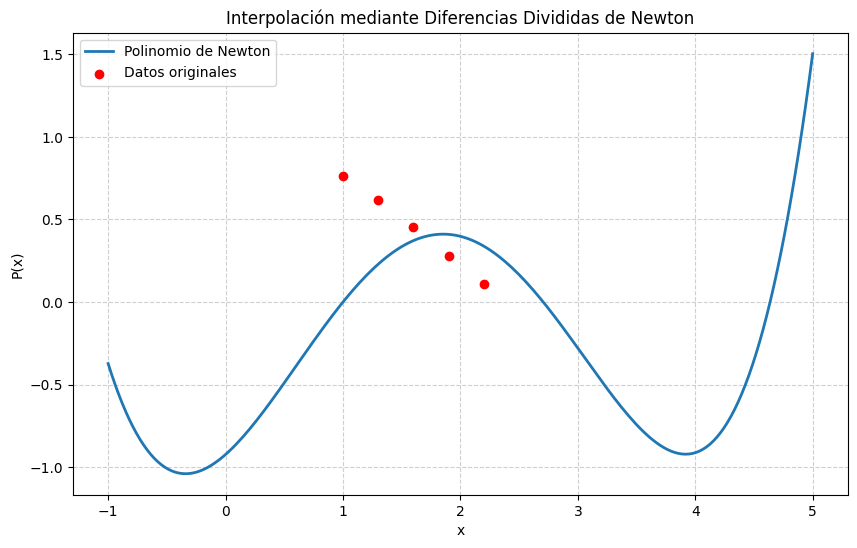

In [83]:
# Convertimos el polinomio simbólico en una función numérica
f = lambdify(t, P, 'numpy')

# Valores para graficar
xx = np.linspace(-1, 5, 200)

# Evaluación del polinomio
yy = f(xx)

# Configuración de la gráfica
plt.figure(figsize=(10, 6))

# Polinomio interpolador
plt.plot(xx, yy, label='Polinomio de Newton', linewidth=2)

# Puntos originales
plt.scatter(x, a, color='red', label='Datos originales', zorder=3)

# Títulos y etiquetas
plt.title('Interpolación mediante Diferencias Divididas de Newton')
plt.xlabel('x')
plt.ylabel('P(x)')

# Cuadrícula y leyenda
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.show()